In [11]:
!pip install opencv-python numpy scikit-learn joblib matplotlib pillow -q



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import os
import cv2
import numpy as np
import joblib
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report


In [13]:
print("Original images:", len(os.listdir("original")))
print("Screen images:", len(os.listdir("screen")))


Original images: 224
Screen images: 194


In [ ]:
import cv2
import numpy as np


def _resize_keep_aspect(img, target=256):
    """Aspect ratio preserve karke resize + pad, taaki moire frequency distort na ho."""
    h, w = img.shape[:2]
    scale = target / max(h, w)
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)

    canvas = np.zeros((target, target, 3), dtype=np.uint8)
    y_off = (target - new_h) // 2
    x_off = (target - new_w) // 2
    canvas[y_off:y_off + new_h, x_off:x_off + new_w] = resized
    return canvas


def _fft_peak_features(gray):
    """
    Fixed band dekhne ke bajaye, FFT magnitude spectrum mein actual
    periodic peaks dhundte hain (moire pattern ka signature).
    """
    f = np.fft.fft2(gray)
    fshift = np.fft.fftshift(f)
    magnitude = 20 * np.log(np.abs(fshift) + 1)

    h, w = magnitude.shape
    cy, cx = h // 2, w // 2

    # DC component (center) ko mask karo — hume periodic peaks chahiye, average brightness nahi
    mask = np.ones_like(magnitude)
    r = 8
    mask[cy - r:cy + r, cx - r:cx + r] = 0
    masked = magnitude * mask

    # Top-K peaks nikaalo — screen recapture mein sharp, high-value peaks honge
    flat = masked.flatten()
    k = 20
    top_k = np.partition(flat, -k)[-k:]
    peak_mean = float(np.mean(top_k))
    peak_std = float(np.std(top_k))

    background_mean = float(np.mean(masked[masked > 0])) if np.any(masked > 0) else 1e-6
    peak_to_background = peak_mean / (background_mean + 1e-6)

    return peak_mean, peak_std, peak_to_background


def _color_banding_score(img):
    """
    Screen recapture (especially compressed/re-encoded) mein color transitions
    kam smooth hote hain — banding/quantization zyada dikhta hai.
    """
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l_channel = lab[:, :, 0].astype(np.float32)

    grad_x = np.abs(np.diff(l_channel, axis=1))
    grad_y = np.abs(np.diff(l_channel, axis=0))

    banding_x = np.mean((grad_x > 1) & (grad_x < 4))
    banding_y = np.mean((grad_y > 1) & (grad_y < 4))
    return float((banding_x + banding_y) / 2)


def _texture_regularity(gray):
    """
    Screen ka pixel-grid ek regular micro-texture create karta hai.
    Simple local variance ka standard deviation (patch-wise) use karke
    texture ki 'regularity' measure karte hain — camera sensor noise
    zyada random hota hai, screen-grid zyada regular.
    """
    h, w = gray.shape
    patch = 16
    variances = []
    for y in range(0, h - patch, patch):
        for x in range(0, w - patch, patch):
            block = gray[y:y + patch, x:x + patch].astype(np.float32)
            variances.append(np.var(block))
    variances = np.array(variances)
    if len(variances) == 0:
        return 0.0
    return float(np.std(variances) / (np.mean(variances) + 1e-6))


def extract_features(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Could not read image: {img_path}")

    img = _resize_keep_aspect(img, target=256)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    
    peak_mean, peak_std, peak_to_background = _fft_peak_features(gray)

    
    laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()

    b, g, r = cv2.split(img)
    color_std = np.std([np.mean(b), np.mean(g), np.mean(r)])

    edges = cv2.Canny(gray, 100, 200)
    edge_density = np.sum(edges > 0) / edges.size

    mean_val = np.mean(gray) + 1e-6
    normalized_contrast = np.std(gray) / mean_val

    
    color_banding = _color_banding_score(img)
    texture_regularity = _texture_regularity(gray)

    feats = [
        peak_mean, peak_std, peak_to_background,
        laplacian_var, color_std, edge_density,
        normalized_contrast, color_banding, texture_regularity,
    ]
    names = [
        "fft_peak_mean", "fft_peak_std", "fft_peak_to_background",
        "laplacian_var", "color_std", "edge_density",
        "normalized_contrast", "color_banding", "texture_regularity",
    ]
    return feats, names


In [15]:
X, y, filenames = [], [], []

for label, folder in enumerate(["original", "screen"]):
    for file in os.listdir(folder):
        path = os.path.join(folder, file)
        try:
            feat, _ = extract_features(path)
            X.append(feat)
            y.append(label)
            filenames.append(path)
        except Exception as e:
            print("skip:", file, e)

X = np.array(X)
y = np.array(y)
print("Total samples:", len(X))
print("Original count:", (y == 0).sum(), "| Screen count:", (y == 1).sum())


Total samples: 418
Original count: 224 | Screen count: 194


In [16]:
X_train, X_test, y_train, y_test, fn_train, fn_test = train_test_split(
    X, y, filenames, test_size=0.2, random_state=42, stratify=y
)

clf = RandomForestClassifier(n_estimators=200, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Original", "Screen"]))


Accuracy: 0.9166666666666666
              precision    recall  f1-score   support

    Original       0.90      0.96      0.92        45
      Screen       0.94      0.87      0.91        39

    accuracy                           0.92        84
   macro avg       0.92      0.91      0.92        84
weighted avg       0.92      0.92      0.92        84



In [17]:
joblib.dump(clf, "model.pkl")
print("Model saved as model.pkl")


Model saved as model.pkl


In [18]:
def predict_baseline(img_path, threshold=0.5):
    feat, _ = extract_features(img_path)
    prob_screen = clf.predict_proba([feat])[0][1]
    label = "Screen Image" if prob_screen >= threshold else "Original Image"
    return label, prob_screen


Prediction: Screen Image (screen probability: 0.960)


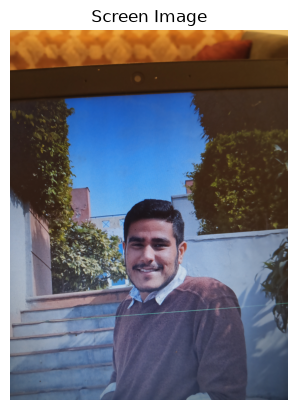

In [19]:
image_path = r"screen/IMG20260712145935.jpg"   # <-- apni test image ka path yahan daalo

result, prob_screen = predict_baseline(image_path)
print(f"Prediction: {result} (screen probability: {prob_screen:.3f})")

plt.imshow(Image.open(image_path))
plt.title(result)
plt.axis("off")
plt.show()


In [20]:
y_pred = clf.predict(X_test)
wrong_idx = np.where(y_test != y_pred)[0]
print(f"Wrong predictions: {len(wrong_idx)} out of {len(y_test)}\n")

for i in wrong_idx:
    actual = "Screen" if y_test[i] == 1 else "Original"
    predicted = "Screen" if y_pred[i] == 1 else "Original"
    print(f"{fn_test[i]:60s} | Actual: {actual:8s} | Predicted: {predicted}")


Wrong predictions: 7 out of 84

screen\IMG20260712145413.jpg                                 | Actual: Screen   | Predicted: Original
original\000000010489.jpg                                    | Actual: Original | Predicted: Screen
screen\IMG20260712145429.jpg                                 | Actual: Screen   | Predicted: Original
screen\IMG20260712145842.jpg                                 | Actual: Screen   | Predicted: Original
screen\WhatsApp Image 2026-07-17 at 14.51.38.jpeg            | Actual: Screen   | Predicted: Original
screen\WhatsApp Image 2026-07-17 at 14.49.31 (1).jpeg        | Actual: Screen   | Predicted: Original
original\000000000562.jpg                                    | Actual: Original | Predicted: Screen


In [21]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42), X, y, cv=5)
print("CV Accuracy per fold:", scores)
print("Mean CV Accuracy:", scores.mean(), "+/-", scores.std())


CV Accuracy per fold: [0.88095238 0.95238095 0.89285714 0.90361446 0.95180723]
Mean CV Accuracy: 0.9163224325874928 +/- 0.03007504153729514
